# Figure 4 | Batch Olympus
Frozen paper data: 19 tasks, six methods, 30 matched repeats, q = 1, 2, 4, 8, 16.


In [1]:
# ======================== SETTINGS ========================
# Put this notebook in notebooks/ and use your existing tidyhebo kernel.
ROOT_OVERRIDE = None
CAMPAIGNS = ("OLY-002",)
EXTRA_RESULT_ROOTS = ()  # Additional campaign directories containing results/trajectories/.
INPUT_SNAPSHOT = True  # Record the frozen source in figure provenance.
QS = (1, 2, 4, 8, 16)
METRICS = ("final_regret", "nAUC")
MODELS = ("random", "optuna", "hebo", "vanilla_gp_qlogei", "yj_qlogei", "qmace_retained")
BASELINE, CVAR_ALPHA = "vanilla_gp_qlogei", .90
MIN_REPEATS, N_BOOT, BOOT_SEED = 30, 10000, 20261105
SAVE_HISTORY = False
SAVE = True
BAND_ALPHA = .12  # Increase to .12–.15 for stronger confidence bands.
LABELS = ("random", "optuna", "HEBO", "qLogEI", "tidyHEBO w/qLogEI", "tidyHEBO")
COLORS = ("tab:blue", "tab:green", "tab:purple", "tab:orange", "tab:brown", "tab:red")
# ==========================================================


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.metadata, inspect, json, os, sys, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

def locate_root():
    if ROOT_OVERRIDE:
        return Path(ROOT_OVERRIDE).expanduser().resolve()
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "src/bo_benchmark").is_dir():
            return p
    raise FileNotFoundError("Set ROOT_OVERRIDE to the benchmark project directory")

ROOT = locate_root()
sys.path.insert(0, str(ROOT / "src"))
from bo_benchmark.analysis.metrics import regret_auc, summarize_auc
from bo_benchmark.analysis.comparison import scores, validate_record, protocol_key
from bo_benchmark.task_catalog import load_catalog
from bo_benchmark.campaign import expand_path

assert QS and len(QS) == len(set(QS)) and all(q >= 1 for q in QS)
assert 0 < CVAR_ALPHA < 1 and MIN_REPEATS >= 1
assert set(METRICS) <= {"nAUC", "final_regret"} and len(set(METRICS)) == len(METRICS)
assert MODELS and len(MODELS) == len(set(MODELS))
assert len(MODELS) == len(LABELS) == len(COLORS)
assert BASELINE in MODELS and N_BOOT >= 1
TASKS = sorted(load_catalog())
def digest(b):
    return hashlib.sha256(b).hexdigest()
def json_bytes(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, allow_nan=False,
                      separators=(",", ":")).encode("utf-8")
metric_sources = {p.name: p for p in {
    Path(inspect.getfile(regret_auc)), Path(inspect.getfile(scores)),
    Path(inspect.getfile(load_catalog))}}
metric_hashes = {n: digest(p.read_bytes()) for n,p in metric_sources.items()}

In [3]:
from bo_benchmark_app.paper import history_records
from bo_benchmark.seeds import SeedManager
all_records, history_manifest = history_records("olympus", ROOT)
history_key = next(key for key in history_manifest["sha256"] if Path(key).name.startswith("olympus."))
snapshot = ROOT / history_key
snapshot_id = history_manifest["sha256"][history_key][:16]
campaign_file = ROOT / "experiments/OLY-002.json"
campaign_configs = {"OLY-002": json.loads(campaign_file.read_text(encoding="utf-8-sig"))} if campaign_file.is_file() else {}


In [4]:
from bo_benchmark.analysis.metrics import olympus_run_table, olympus_statistics
df = olympus_run_table(all_records, TASKS, MODELS, QS, SeedManager(42,30).seeds)
coverage = df.groupby(["task","optimizer","q"]).size().rename("completed").reset_index()


In [5]:
# Frozen histories are read directly; no copy or checkpoint is created.


## Как считается Mean paired difference

Обозначения: $t$ — задача, $m$ — метод, $b$ — baseline **GP + qLogEI** (`vanilla_gp_qlogei`),
$q$ — размер батча, $s$ — seed. $y_{t,m,q,s}$ — значение выбранной метрики отдельного запуска
(`final_regret` или `nAUC`). Обе метрики минимизируются.

**Сопоставление повторов.** Для каждой задачи код оставляет пересечение seeds, доступных
одновременно у всех выбранных методов и всех выбранных $q$. Обозначим его $S_t$,
а число повторов — $n_t$. Требуется не менее `MIN_REPEATS` общих seeds.
Baseline всегда берётся **на той же задаче и при том же q**.

### Вторая колонка: разность средних

Сначала для каждого метода усредняем метрику по общим seeds внутри задачи:

$$
\bar y_{t,m,q}=\frac{1}{n_t}\sum_{s\in S_t}y_{t,m,q,s}.
$$

Затем вычитаем среднее baseline на той же задаче и усредняем разности по задачам:

$$
d_{t,m,q}=\bar y_{t,m,q}-\bar y_{t,b,q},\qquad
D_{m,q}=\frac{1}{T}\sum_{t=1}^{T}d_{t,m,q}.
$$

Точка на графике — $D_{m,q}$. При одинаковом наборе seeds разность средних равна
среднему попарных разностей запусков:

$$
d_{t,m,q}=\frac{1}{n_t}\sum_{s\in S_t}
\left(y_{t,m,q,s}-y_{t,b,q,s}\right).
$$

Отсюда слово **paired**: совпадают задача, размер батча и seed.
Все задачи имеют одинаковый вес $1/T$, даже если у одной 15 повторов, а у другой 16.
Это разность в единицах метрики, без деления на baseline и без перевода в проценты.
Например, среднее 0.10 у метода и 0.13 у baseline даёт разность −0.03 для этой задачи.
Отрицательные значения означают преимущество метода, положительные — преимущество baseline.
У baseline разность и её интервал равны нулю.

### Третья колонка: разность CVaR90

По тем же общим повторам отдельно для каждого метода и задачи вычисляется CVaR90
через `bo_benchmark.analysis.metrics.summarize_auc`:

$$
c_{t,m,q}=\operatorname{mean}\{y_{t,m,q,s}:
 y_{t,m,q,s}\geq Q_{0.90}(y_{t,m,q,\cdot})\},\qquad
D^{\mathrm{CVaR}}_{m,q}=\frac{1}{T}\sum_{t=1}^{T}
(c_{t,m,q}-c_{t,b,q}).
$$

Это среднее значений верхнего, худшего хвоста метрики: порог задаёт
`numpy.quantile`, включаются все значения на пороге и выше, включая совпадения.
При 15–16 повторах без совпадений в хвост обычно попадают два худших запуска.
Сначала считаются два CVaR, затем их разность; это **не CVaR попарных разностей**.
Худшие seeds у метода и baseline могут различаться. Значения разных задач не смешиваются
при определении хвоста. Здесь отрицательная разность также означает преимущество метода.

### Полупрозрачные полосы: 95% интервалы

В каждой из `N_BOOT=10000` bootstrap-выборок выбираются $T$ задач с возвращением
и усредняются их $d_{t,m,q}$ (или разности CVaR). Границы полосы — квантили 2.5% и 97.5%
этих средних. Индексы задач общие для всех методов, q и метрик; `BOOT_SEED` фиксирован.
Это **поточечные интервалы bootstrap по задачам**, условные на наблюдённых повторах:
seeds повторно не выбираются. Они не являются одновременными интервалами для всей
картинки и не учитывают отдельно неопределённость оценки CVaR по малому числу повторов.


In [6]:
task_metrics, summary = olympus_statistics(df, MODELS, QS, baseline=BASELINE,
    alpha=CVAR_ALPHA, draws=N_BOOT, seed=BOOT_SEED)
means = task_metrics.pivot(index=["task","optimizer","q"],columns="metric",values="mean").reset_index()
tails = task_metrics.pivot(index=["task","optimizer","q"],columns="metric",values="CVaR").reset_index()
display(summary)


,metric,optimizer,q,panel,mean,low,high
0,final_regret,random,1,rank,5.684211,5.315789,6.000000
1,final_regret,optuna,1,rank,3.947368,3.315789,4.526316
2,final_regret,hebo,1,rank,3.263158,2.631579,3.894737
3,final_regret,vanilla_gp_qlogei,1,rank,3.736842,3.210526,4.263158
4,final_regret,yj_qlogei,1,rank,2.684211,2.157895,3.263158
...,...,...,...,...,...,...,...
175,nAUC,optuna,16,cvar_delta,2.078513,-0.114331,4.445728
176,nAUC,hebo,16,cvar_delta,9.990007,7.018056,13.159665
177,nAUC,vanilla_gp_qlogei,16,cvar_delta,0.000000,0.000000,0.000000
178,nAUC,yj_qlogei,16,cvar_delta,0.382403,-0.550287,1.505240


In [7]:
# Final print size: 172 mm wide. Fonts stay 8–10 pt when inserted at this width.
style = {"font.family":"DejaVu Sans", "font.size":8, "font.weight":"normal",
         "axes.labelweight":"normal", "axes.titleweight":"bold", "axes.linewidth":.85,
         "axes.titlesize":8.3, "axes.labelsize":8, "xtick.labelsize":8, "ytick.labelsize":8,
         "text.color":"#202020", "axes.labelcolor":"#202020",
         "xtick.color":"#202020", "ytick.color":"#202020",
         "pdf.fonttype":42, "ps.fonttype":42}
with plt.rc_context(style):
    fig = plt.figure(figsize=(172/25.4, 123/25.4), layout="constrained")
    subfigs = fig.subfigures(len(METRICS), 1, hspace=.035)
    axes = []
    for i, (metric, sf) in enumerate(zip(METRICS, np.atleast_1d(subfigs))):
        sf.suptitle("Final regret" if metric == "final_regret" else "nAUC",
                    x=.025, ha="left", fontsize=10, weight="bold")
        row = sf.subplots(1, 3); axes.append(row)
        for j, panel in enumerate(("rank", "mean_delta", "cvar_delta")):
            ax = row[j]
            for model, label, color in zip(MODELS, LABELS, COLORS):
                t = summary.query("metric == @metric and panel == @panel and optimizer == @model").set_index("q").loc[list(QS)]
                ax.fill_between(QS, t.low, t.high, color=color, alpha=BAND_ALPHA, linewidth=0, zorder=1)
                ax.plot(QS, t["mean"], color=color, lw=1.75, marker="o", ms=3.7,
                        mec="white", mew=.4, label=label, zorder=3)
            title = ("Mean task rank ↓", "Δ Mean vs qLogEI ↓", f"Δ CVaR{CVAR_ALPHA*100:g} vs qLogEI ↓")[j]
            ax.set_title(f"{chr(65+i*3+j)}  {title}", loc="left", pad=5)
            ax.set_xscale("log", base=2); ax.set_xticks(QS, [str(q) for q in QS]); ax.set_xlim(.9,17.8)
            if i == len(METRICS)-1: ax.set_xlabel("Batch size q", labelpad=3)
            if panel == "rank":
                ax.set_ylim(.85,len(MODELS)+.15); ax.set_yticks(range(1,len(MODELS)+1))
            else:
                ax.axhline(0, color="#555555", lw=.9, ls=(0,(3,2)), zorder=2)
                ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5))
            ax.tick_params(width=.85, length=3, pad=2)
            ax.grid(axis="y", color="#dddddd", lw=.45); ax.set_axisbelow(True)
            ax.spines[["top","right"]].set_visible(False)
    handles, labels = axes[0][0].get_legend_handles_labels()
    # Matplotlib fills legend columns vertically: reverse columns, retaining row order.
    legend_order = np.concatenate(np.array_split(np.arange(len(handles)), 3)[::-1])
    # Put tidyHEBO first within the leftmost column.
    legend_order[[0, 1]] = legend_order[[1, 0]]
    handles = [handles[i] for i in legend_order]
    labels = [labels[i] for i in legend_order]
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False,
               fontsize=7.7, handlelength=2.3, columnspacing=1.2, handletextpad=.55)
plt.show()


./figures/olympus


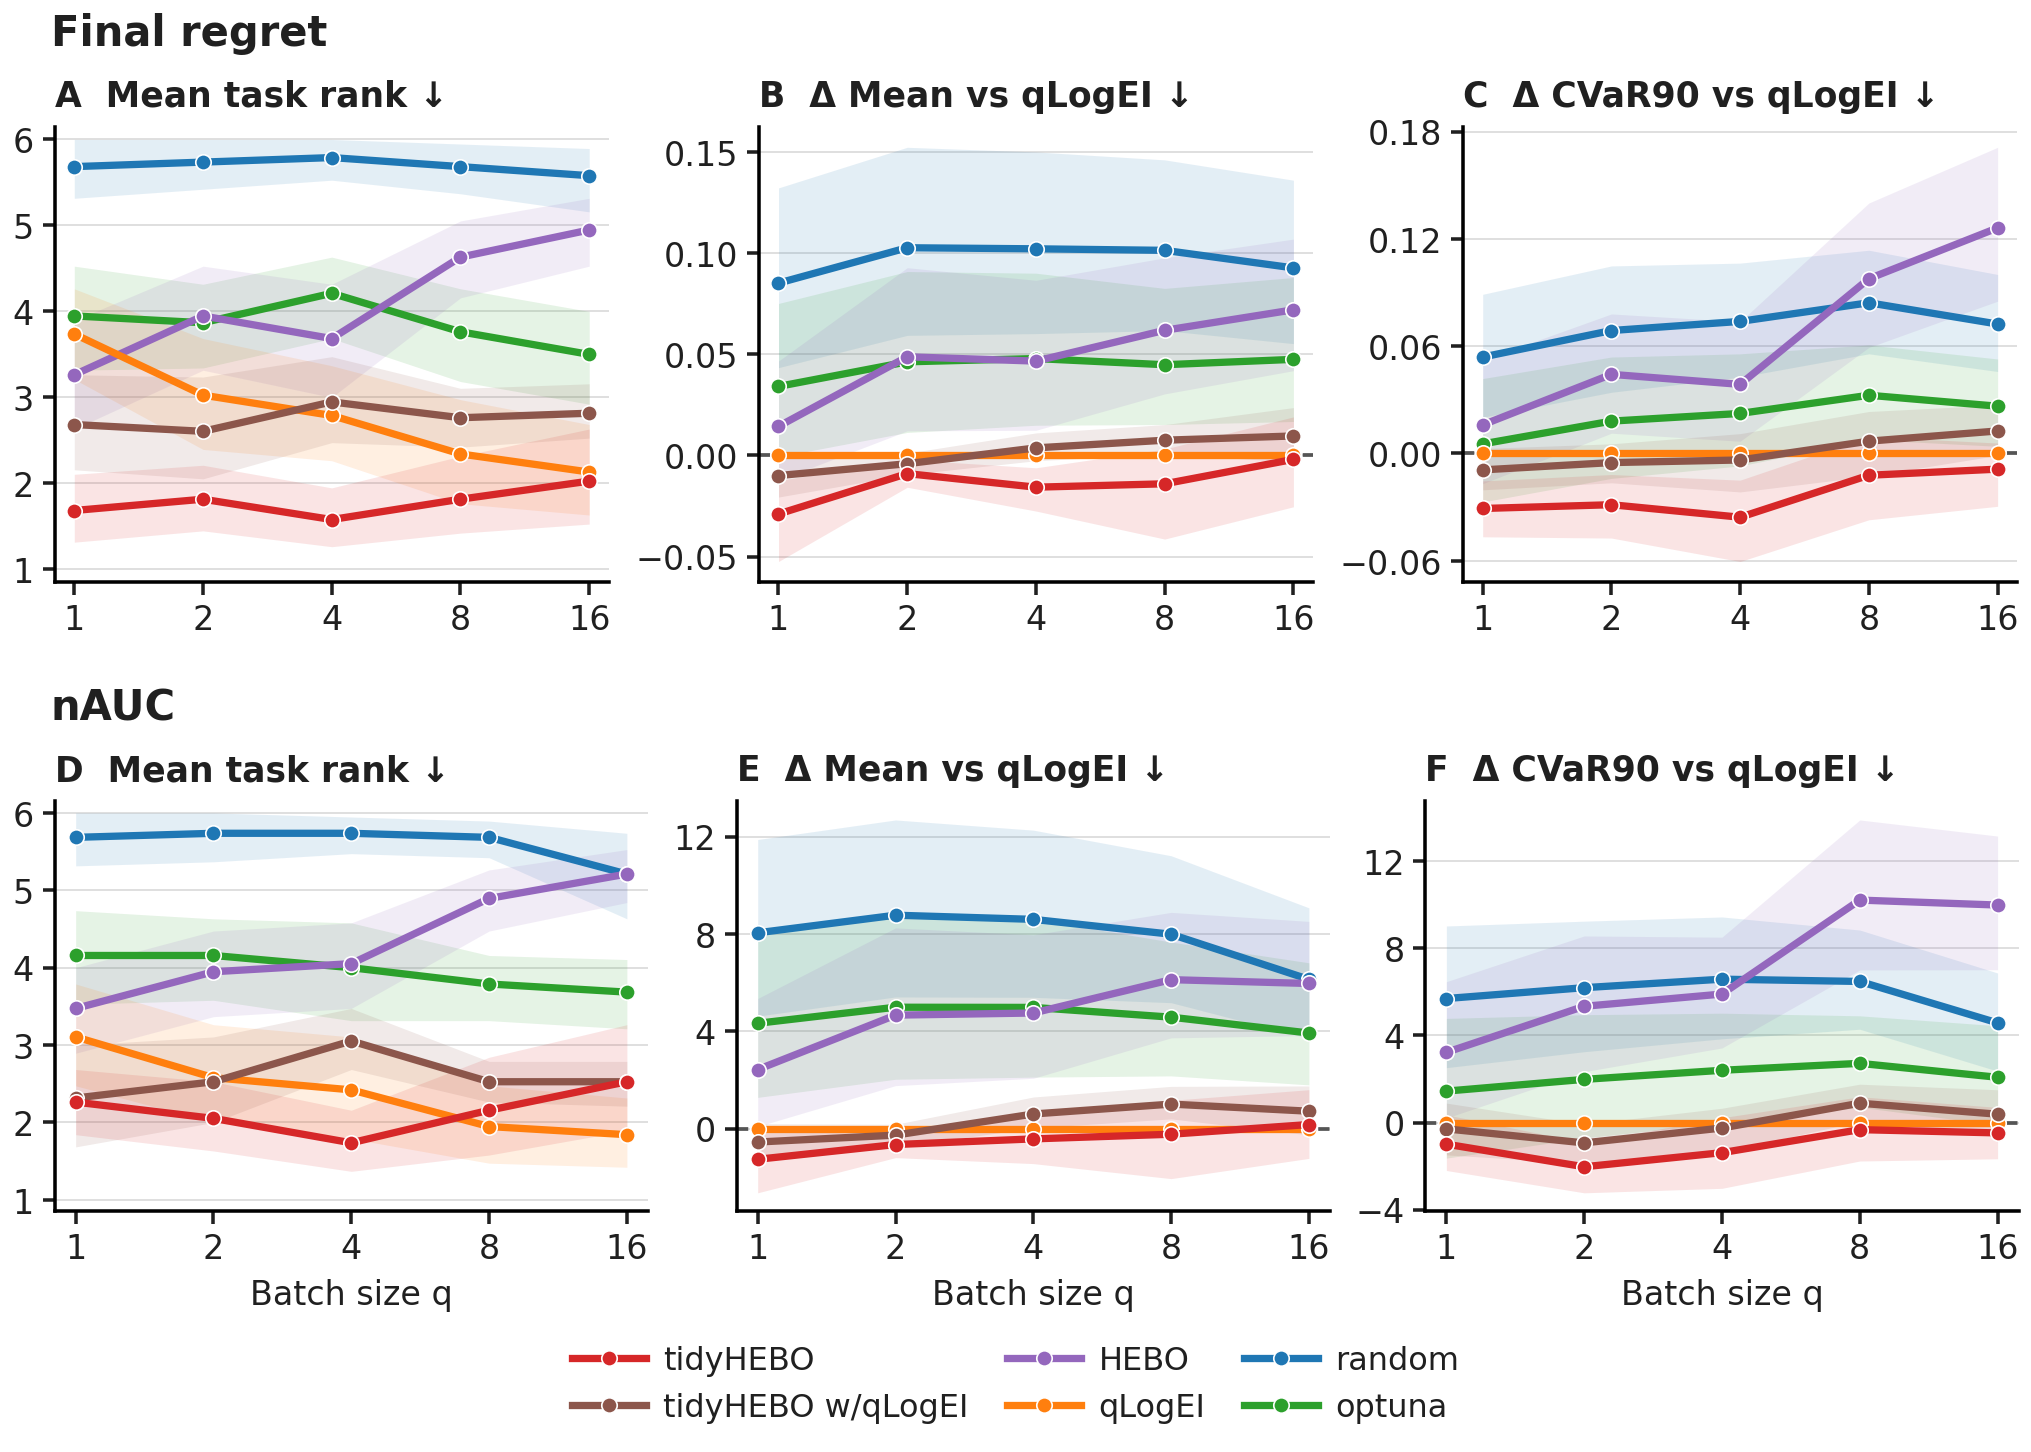

In [8]:
if SAVE:
    OUT = ROOT / "figures" / "olympus"
    OUT.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf", "svg"):
        fig.savefig(OUT / f"Figure_4_Olympus_batch.{ext}", dpi=300, facecolor="white")
    df.to_csv(OUT / "paired_run_metrics.csv", index=False)
    coverage.to_csv(OUT / "coverage.csv", index=False)
    summary.to_csv(OUT / "figure_values.csv", index=False)
    means.to_csv(OUT / "task_means.csv", index=False); tails.to_csv(OUT / "task_CVaR.csv", index=False)
    (OUT / "analysis_manifest.json").write_text(json.dumps(dict(snapshot=snapshot.relative_to(ROOT).as_posix() if (SAVE_HISTORY or INPUT_SNAPSHOT) else None,
        snapshot_id=snapshot_id, metric_hashes=metric_hashes, campaign_configs=campaign_configs,
        q=QS, models=MODELS, metrics=METRICS, baseline=BASELINE, cvar_alpha=CVAR_ALPHA,
        cvar="repository mean(values >= quantile(alpha)), per task over repeats",
        bootstrap_samples=N_BOOT, bootstrap_seed=BOOT_SEED, interval="pointwise 95% paired task bootstrap"), indent=2))
    print(OUT)

# Display the generated figure when running in Jupyter.
from IPython import get_ipython
if get_ipython() is not None:
    from IPython.display import Image, display
    display(Image(filename=str(ROOT / 'figures/olympus/Figure_4_Olympus_batch.png')))
